# Univariate Analysis

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducible sample customer data
rng = np.random.default_rng(42)
n = 120
df = pd.DataFrame({
    "Customer_ID": np.arange(1001, 1001 + n),
    "Age": np.clip(rng.normal(35, 11, n).round(), 18, 70).astype(int),
    "Monthly_Spend": np.clip(rng.gamma(3, 950, n).round(2), 200, 14000),
    "Orders": rng.poisson(5, n),
    "Department": rng.choice(["Electronics", "Clothing", "Grocery"], n, p=[.35,.40,.25]),
    "Membership": rng.choice(["Basic", "Silver", "Gold"], n, p=[.50,.30,.20]),
    "Purchased": rng.choice(["Yes", "No"], n, p=[.65,.35])
})
print(df.head())
print("Shape:", df.shape)

   Customer_ID  Age  Monthly_Spend  Orders   Department Membership Purchased
0         1001   38        1254.16       5  Electronics     Silver        No
1         1002   24        2890.18       8     Clothing       Gold       Yes
2         1003   43        4062.27       7  Electronics     Silver       Yes
3         1004   45        5548.99       2  Electronics      Basic        No
4         1005   18        1664.82       6     Clothing      Basic        No
Shape: (120, 7)


# 1. Mean
# Definition
The mean is the average value of a numerical variable. It is calculated by adding all values and dividing by the number of observations. The mean can be affected by unusually high or low values. It is useful for comparing average values across different customer groups.

# Business Example
A retail manager calculates the average monthly spending of customers to estimate typical revenue per customer. This helps with planning sales targets and budgets. If average spending increases, the business can investigate whether more customers are purchasing or individual purchases are larger.

# AI/ML Use
The mean summarizes the central level of a numerical feature. It can also be used to fill missing numerical values when the distribution is reasonably balanced. During feature scaling, the mean is used to center numerical values around zero. Training-set means should be used to avoid data leakage.

# Python Example

In [2]:
print("Mean monthly spend:", df["Monthly_Spend"].mean())

Mean monthly spend: 3068.6474166666662


# Explanation
The result is the average monthly spending across customers. Compare it with the median to check whether unusually high spending may be pulling the mean upward. The value is measured in the same units as the original column. Check the number of valid records before interpreting it.

# 2. Median
# Definition
The median is the middle value after sorting a numerical variable. For an even number of values, it is the average of the two middle values. It is less sensitive to extreme observations than the mean. Half of the valid observations are at or below the median and half are at or above it.

# Business Example
A company reports median customer spending when a few customers make very large purchases. This gives a useful picture of the middle customer. The median can provide a fairer reference for setting customer spending segments.

# AI/ML Use
Median imputation is often useful for numerical features with outliers. It preserves a typical central value without being strongly influenced by extreme observations. A robust preprocessing pipeline may replace missing values with the training-data median.

# Python Example

In [3]:
print("Median monthly spend:", df["Monthly_Spend"].median())

Median monthly spend: 2708.67


# Explanation
This is the middle spending value. A mean much larger than the median may suggest right-skewed spending. Compare this number with the mean before choosing a typical spending value.

# 3. Mode
# Definition
The mode is the most frequently occurring value. It can describe both numerical and categorical variables. A variable may have more than one mode. For categories, it identifies the label that appears most often.

# Business Example
A store identifies the most common number of orders placed by customers. This helps the team understand typical purchasing frequency. A popular order frequency can guide inventory and staffing decisions.

# AI/ML Use
The mode can be used to fill missing categorical values, though it may increase the majority class. It also helps describe common customer behavior. Mode-based imputation is simple, but it may hide rare categories.

# Python Example

In [4]:
print("Most common order count(s):", df["Orders"].mode().tolist())


Most common order count(s): [5]


# Explanation
The displayed value or values occur most frequently. Several modes are possible when frequencies are tied. If multiple values tie for the highest frequency, more than one mode can exist.

# 4. Minimum
# Definition
The minimum is the smallest observed value of a variable. It helps identify the lower boundary of the collected data. A very small value may need a quality check. It shows the smallest valid observed value, not necessarily the smallest possible value.

# Business Example
A retailer checks the lowest monthly spending amount to understand small transactions. Unexpected negative spending could indicate incorrect data. An unexpectedly low price or age may indicate a data-entry error.

# AI/ML Use
Minimum values help identify potential invalid inputs before model training. Domain rules are needed to decide whether a small value is actually wrong. Minimum values help identify suspicious inputs before model training.

# Python Example

In [5]:
print("Minimum age:", df["Age"].min())

Minimum age: 18


# Explanation
The output shows the youngest age recorded. Compare it with the business rules for customer eligibility. Review unusually small observations rather than deleting them automatically.

# 5. Maximum
# Definition
The maximum is the largest observed value of a numerical variable. It shows the upper boundary of the collected observations. Very large values may be valid or may require investigation. It represents the largest recorded value in the chosen feature.

# Business Example
A company finds the highest monthly spend to identify high-value customers. The team checks whether unusually large values are genuine. The largest purchase can reveal high-value customers or unusual transactions.

# AI/ML Use
Maximum values are useful for screening extreme feature values. They can guide outlier checks and feature scaling decisions. Extreme maxima may influence scaling and some model types.

# Python Example

In [6]:
print("Maximum monthly spend:", df["Monthly_Spend"].max())

Maximum monthly spend: 10240.83


# Explanation
This is the highest spending value. It is not automatically an error just because it is large. Investigate whether the highest value is realistic or an error.

# 6. Range
# Definition
The range measures the distance between the maximum and minimum values. It is calculated as maximum minus minimum. It is easy to understand but sensitive to extreme observations. Range is calculated as maximum minus minimum. It describes the full observed spread.

# Business Example
A manager compares the lowest and highest order counts to see how much customer activity varies. A large range may suggest very different customer groups. A large spending range may suggest that customers have very different purchasing patterns.

# AI/ML Use
Range provides a quick view of feature spread. It can flag variables needing closer distribution or outlier analysis. The range can flag potential outliers before feature transformation.

# Python Example

In [7]:
print("Order range:", df["Orders"].max() - df["Orders"].min())

Order range: 11


# Explanation
The output shows the gap between the most and least orders. It does not describe how values are distributed between those limits. Because it uses only two observations, range can change sharply due to one extreme value.

# 7. Variance
# Definition
Variance measures the average squared spread of values around their mean. Larger variance means observations are more dispersed. Pandas uses sample variance by default (ddof=1). Variance measures average squared deviation from the mean; its units are squared.

# Business Example
A business measures how widely monthly customer spending differs. Higher variation means customer spending is less consistent. A retailer can compare how consistently customers spend across product groups.

# AI/ML Use
Variance can reveal features with very different scales. It helps explain why feature scaling may be useful for some ML algorithms. Low-variance features sometimes carry little useful predictive information.

# Python Example

In [8]:
print("Sample variance of age:", df["Age"].var())

Sample variance of age: 71.28711484593838


# Explanation
The result is measured in squared years. It describes variation but is harder to interpret directly than standard deviation. Larger variance means observations are more spread out, but compare variables carefully because scales differ.

# 8. Standard Deviation
Definition
Standard deviation measures the typical spread around the mean in the original units. It is the square root of variance. A larger value indicates more variation. Standard deviation is the square root of variance and uses the original units.

# Business Example
A sales team measures how much monthly spending typically differs from the average. This helps evaluate whether spending is stable or widely spread. A higher spending standard deviation indicates less predictable customer spending.

# AI/ML Use
Standard deviation is used in z-score standardization and anomaly detection. Models that depend on feature scale often benefit from standardized inputs. Standardization divides deviations from the mean by standard deviation.

# Python Example

In [9]:
print("Sample standard deviation of age:", df["Age"].std())

Sample standard deviation of age: 8.443169715571184


# Explanation
The result is expressed in years. A larger standard deviation means customer ages are more widely spread. A small value means most observations lie closer to the mean; inspect the distribution for context.

# 9. Quartiles
# Definition
Quartiles split sorted data into four parts. Q1 is the 25th percentile, Q2 is the median, and Q3 is the 75th percentile. They help describe the middle half of a distribution. Quartiles split sorted observations into four sections. The first and third quartiles define the middle half.

# Business Example
A retailer uses spending quartiles to understand lower-, middle-, and higher-spending customers. The middle 50% lies between Q1 and Q3. Retailers can group customers into lower, middle, and higher spending segments.

# AI/ML Use
Quartiles support the interquartile range (IQR) method for detecting potential outliers. They also help summarize skewed numerical features. The interquartile range can help detect unusually distant values.

# Python Example

In [10]:
print(df["Monthly_Spend"].quantile([0.25, 0.50, 0.75]))

0.25    1829.105
0.50    2708.670
0.75    3902.180
Name: Monthly_Spend, dtype: float64


# Explanation
Q1, Q2, and Q3 mark the 25%, 50%, and 75% positions. The gap between Q1 and Q3 is the IQR. The middle 50% of observations falls between the first and third quartiles.

# 10. Percentiles
# Definition
A percentile shows the value below which a given percentage of observations fall. The 90th percentile is a threshold with about 90% of values at or below it. Percentiles are useful for comparing relative positions. The pth percentile is a threshold at or below which roughly p percent of values fall.

# Business Example
A store identifies the 90th percentile of customer spending to help define a high-spending segment. This avoids choosing an arbitrary spending cutoff. A business can identify its top-spending customers using the 90th percentile.

# AI/ML Use
Percentiles can support clipping extreme feature values or creating business segments. Any clipping threshold should be selected using training data only. Percentile thresholds can support robust clipping and feature binning.

# Python Example

In [11]:

print("90th percentile of spend:", df["Monthly_Spend"].quantile(0.90))

90th percentile of spend: 5608.131000000002


# Explanation
About 90% of observed spending values are at or below this threshold. It can help identify the highest-spending 10%. A percentile describes relative position, not the percentage of the value itself.

# 11. Skewness
# Definition
Skewness describes the asymmetry of a numerical distribution. Positive skew means a longer tail on the right; negative skew means a longer tail on the left. A value near zero suggests approximate symmetry, not necessarily normality. Positive skew has a longer right tail; negative skew has a longer left tail.

# Business Example
A company studies spending data and notices that most customers spend moderately while a few spend a lot. This can produce positive skew. Customer spending is often right-skewed when a few customers spend much more.

# AI/ML Use
Highly skewed features may benefit from a suitable transformation such as log1p for nonnegative data. The choice depends on the model and data. Highly skewed features may benefit from log or power transformations.

# Python Example

In [12]:
print("Spending skewness:", df["Monthly_Spend"].skew())

Spending skewness: 1.2715937331086038


# Explanation
Positive output suggests a longer right tail; negative output suggests a longer left tail. Inspect a histogram before deciding on a transformation. Interpret the sign together with a histogram; one number cannot show every distribution detail.

# 12. Kurtosis
# Definition
Kurtosis describes aspects of a distribution’s tail heaviness and extreme values. Pandas reports excess kurtosis, where a normal distribution has a reference value of zero. Higher values can indicate heavier tails. Kurtosis summarizes tail heaviness and sensitivity to extreme observations.

# Business Example
A finance team checks whether transaction amounts contain unusually extreme observations. Heavy tails can make average-based summaries less representative. A retailer can investigate whether spending has unusually extreme transactions.

# AI/ML Use
Kurtosis can help flag distributions with many extreme observations. It is a diagnostic, not a stand-alone test that a feature is invalid. Heavy tails may indicate outliers that affect regression errors and preprocessing.

# Python Example

In [13]:
print("Excess kurtosis of spend:", df["Monthly_Spend"].kurt())


Excess kurtosis of spend: 2.008092413121794


# Explanation
Values above zero suggest heavier tails than a normal reference, while negative values suggest lighter tails. Interpret alongside plots and business knowledge. Pandas reports excess kurtosis, where a normal distribution has a reference value near zero.

# 13. Histogram
# Definition
A histogram divides numerical values into intervals called bins and counts observations in each bin. It shows shape, spread, and possible skewness. The number of bins affects how the plot looks. A histogram groups numerical observations into bins and displays their frequencies.

# Business Example
A sales manager plots customer spending to see whether most purchases fall into low, medium, or high ranges. This can reveal spending clusters. A store can see whether most customers fall into low, medium, or high spending ranges.

# AI/ML Use
Histograms help examine numerical features before modeling. They can reveal skewness, gaps, and possible outliers that may influence preprocessing. Histograms reveal skew, clusters, and possible outliers before feature engineering.

# Python Example

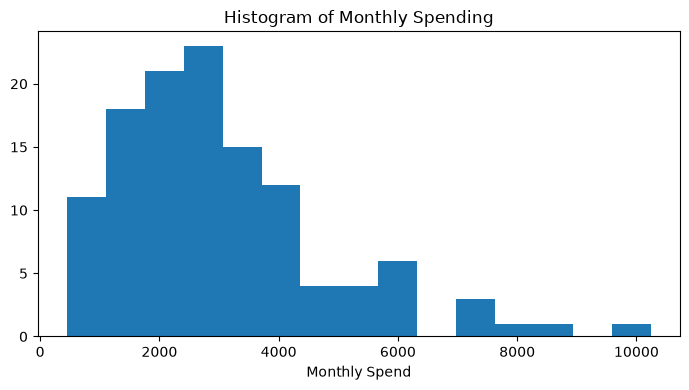

In [14]:
plt.figure(figsize=(7,4))
plt.hist(df["Monthly_Spend"], bins=15)
plt.title("Histogram of Monthly Spending")
plt.xlabel("Monthly Spend")
plt.tight_layout()
plt.show()

# Explanation
Look for where most observations are concentrated and whether the tail extends farther on one side. Spending is often right-skewed. Bin width changes the appearance; compare several sensible bin choices.

# 14. KDE / Density Plot
# Definition
A kernel density estimate (KDE) is a smoothed estimate of a numerical distribution. Unlike a histogram, it draws a continuous density curve. Smoothing can hide small details, especially in small samples. A KDE curve provides a smooth estimate of a numerical variable’s distribution.

# Business Example
A business plots the smoothed distribution of customer ages to understand common age ranges. The curve makes broad patterns easier to compare. It helps a business compare the overall shapes of spending patterns.

# AI/ML Use
Density plots help visualize feature distributions and compare groups. They are descriptive and should not be treated as exact probabilities at single points. Density curves can show potential multimodal patterns before modeling.

# Python Example

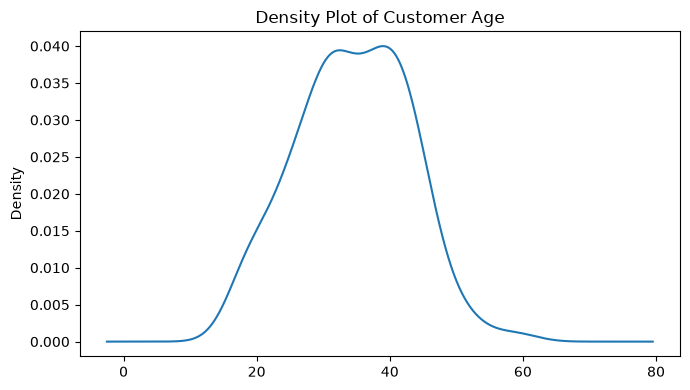

In [15]:
plt.figure(figsize=(7,4))
df["Age"].plot.kde()
plt.title("Density Plot of Customer Age")
plt.tight_layout()
plt.show()

# Explanation
Peaks indicate age ranges with relatively greater concentration. The area under the estimated density curve is one. The curve is an estimate, and smoothing can hide sharp peaks or suggest values outside valid bounds.

# 15. Box Plot
Definition
A box plot displays the median, quartiles, and whiskers of a numerical feature. Points beyond the whiskers are flagged as potential outliers under the chosen rule. They are not automatically errors. A box plot summarizes median, quartiles, whiskers, and potential outliers.

# Business Example
A retailer uses a box plot to compare typical spending with unusually high transactions. It helps identify purchases that need closer review. A business can quickly compare spending distributions between customer segments.

# AI/ML Use
Box plots support outlier screening before training. Removing flagged values without business checks can discard useful information. Box plots can reveal unusual values that need investigation before training.

# Python Example

C:\Users\Yuvasri\AppData\Local\Temp\ipykernel_24916\130595356.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df["Monthly_Spend"], vert=False)


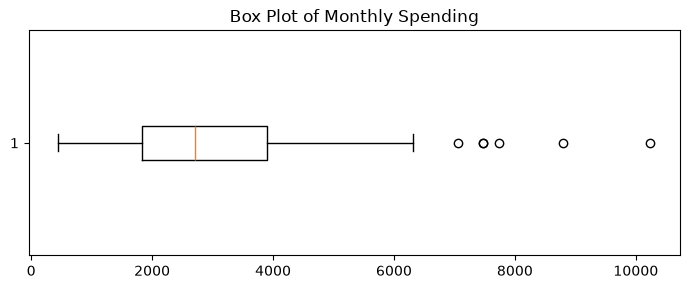

In [16]:
plt.figure(figsize=(7,3))
plt.boxplot(df["Monthly_Spend"], vert=False)
plt.title("Box Plot of Monthly Spending")
plt.tight_layout()
plt.show()

# Explanation
The central line is the median and the box spans Q1 to Q3. Individual points beyond whiskers are candidates for investigation. Points beyond whiskers are possible outliers, not automatic errors.

# 16. Frequency
Definition
Frequency is the number of times a category or value occurs. It tells us which groups are common or rare. Frequency can be expressed as counts or proportions. Frequency is the number of times a category or value occurs.

# Business Example
A company counts customers in each membership tier to understand the size of its customer segments. This helps plan targeted offers. Counting purchases by department shows which department is most active.

# AI/ML Use
Frequency checks reveal class imbalance in categorical predictors and targets. Rare categories may require careful handling during encoding. Class frequencies help reveal imbalance in classification datasets.

# Python Example

In [17]:
print(df.groupby("Membership").size())

Membership
Basic     67
Gold      23
Silver    30
dtype: int64


# Explanation
The output shows how many customers belong to each tier. Larger counts indicate more common categories. Check whether missing categories are included in the frequency count.

# 17. Unique Values
# Definition
Unique values are the distinct categories or values present in a column. Checking them helps discover unexpected labels and inconsistent spelling. The number of unique values is called cardinality. Unique values are the distinct entries present in a column.

# Business Example
A retailer checks unique department names to ensure categories are consistent. Labels such as Electronics and electronics may need standardization. A company checks department names to find inconsistent spelling or unexpected labels.

# AI/ML Use
Unique-value inspection helps plan categorical encoding. High-cardinality columns such as customer IDs generally should not be treated as ordinary categories. High-cardinality categorical features may require special encoding strategies.

# Python Example

In [18]:
print("Unique departments:", df["Department"].unique()); print("Number of unique departments:", df["Department"].nunique())

Unique departments: <ArrowStringArray>
['Electronics', 'Clothing', 'Grocery']
Length: 3, dtype: str
Number of unique departments: 3


# Explanation
The first result lists observed department labels; the second counts them. Unexpected labels can indicate data-quality issues. Unexpected unique labels can reveal data-cleaning needs.

# 18. Value Counts
Definition
Value counts reports how many times each distinct value appears. By default, Pandas sorts counts from most common to least common. It is especially useful for categorical features. Value counts returns the frequency of each distinct value, usually sorted by count.

# Business Example
A manager checks which department has the most customers. The results help prioritize marketing and stock planning. A retailer can rank the most common customer membership types.

# AI/ML Use
Value counts reveal dominant classes and uncommon categories. They help evaluate whether category encoding or imbalance handling is needed. Value counts can reveal rare classes and possible target imbalance.

# Python Example

In [19]:
print(df["Department"].value_counts())

Department
Electronics    44
Clothing       42
Grocery        34
Name: count, dtype: int64


# Explanation
The most frequent department appears first. Compare categories to see whether the distribution is balanced. Compare counts with total nonmissing rows to interpret prevalence correctly.

# 19. Percentage Distribution
# Definition
Percentage distribution shows each category’s share of the total. Percentages are easier to compare when datasets have different sizes. The shares add up to approximately 100%. Percentage distribution expresses each category’s share of the total.

# Business Example
A business reports the percentage of Basic, Silver, and Gold members. This helps understand the customer mix at a glance. A business can report the share of customers in each department.

# AI/ML Use
Percentage distributions reveal target-class imbalance and categorical feature composition. They help decide whether accuracy alone is a suitable evaluation metric. Class proportions help select suitable evaluation metrics and sampling methods.

# Python Example

In [20]:
print((df["Membership"].value_counts(normalize=True) * 100).round(2))

Membership
Basic     55.83
Silver    25.00
Gold      19.17
Name: proportion, dtype: float64


# Explanation
Each value is a percentage of customers in that tier. Large differences show which membership categories dominate. Percentages are easier to compare across datasets of different sizes.

# 20. Bar Chart
# Definition
A bar chart compares values across categories using bar lengths. It is useful for counts or other summarized values. Categories are displayed as separate bars. A bar chart displays a numeric summary for each category using separate bars.

# Business Example
A store compares customer counts by department in a bar chart. The longest bar represents the largest customer group. A business can compare average spending across departments.

# AI/ML Use
Bar charts help compare category frequencies before encoding or modeling. They make rare and dominant categories easy to spot. Category summaries can expose relationships worth investigating in feature selection.

# Python Example

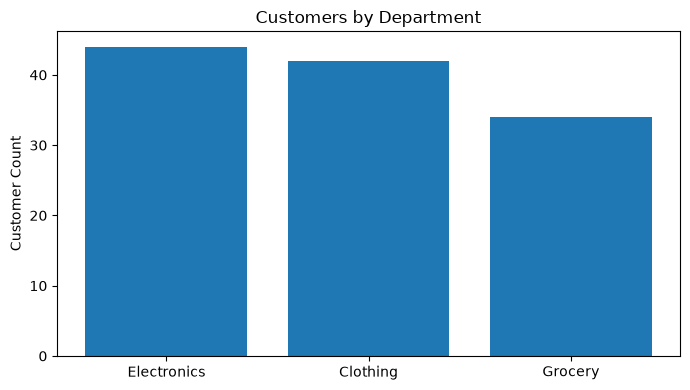

In [21]:
counts = df["Department"].value_counts()
plt.figure(figsize=(7,4))
plt.bar(counts.index, counts.values)
plt.title("Customers by Department")
plt.ylabel("Customer Count")
plt.tight_layout()
plt.show()

# Explanation
Bar height shows the number of customers in each department. The chart makes differences in category sizes clear. Always label the measured quantity; bar height is not necessarily a count.

# 21. Count Plot
# Definition
A count plot automatically draws bars showing the number of records in each category. It is convenient for quick categorical EDA. It is similar to a bar chart of value counts. A count plot draws the number of records belonging to each category.

# Business Example
A marketing team creates a count plot of membership tiers. The chart immediately shows which tier is most common. Managers can see which customer group contributes the most records.

# AI/ML Use
Count plots help inspect categorical inputs and target balance. Very small groups may require extra care when splitting datasets. Count plots make imbalanced categorical labels easy to spot.

# Python Example

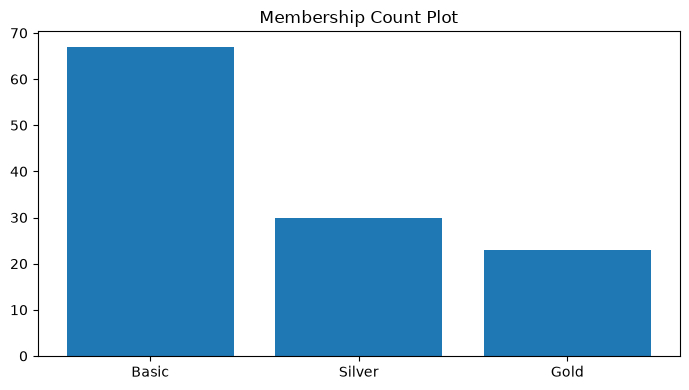

In [22]:
plt.figure(figsize=(7,4))
plt.bar(df["Membership"].value_counts().reindex(["Basic", "Silver", "Gold"]).index, df["Membership"].value_counts().reindex(["Basic", "Silver", "Gold"]).values)
plt.title("Membership Count Plot")
plt.tight_layout()
plt.show()

# Explanation
The tallest bar represents the most common membership tier. Compare the bar heights to see category imbalance. A taller bar means more observations, not necessarily better performance.

# 22. Pie Chart
# Definition
A pie chart displays categories as portions of a circle. It works best for a small number of categories with clear differences. For many categories, a bar chart is usually easier to read. A pie chart shows how categories contribute to a whole.

# Business Example
A manager shows the share of customers who purchased versus those who did not. A pie chart gives a quick view of the two groups. A company can display the share of customers in a few membership groups.

# AI/ML Use
A pie chart can summarize a binary target distribution for initial EDA. Use actual counts or percentages for more precise comparisons. A pie chart can communicate class balance when there are only a few categories.

# Python Example

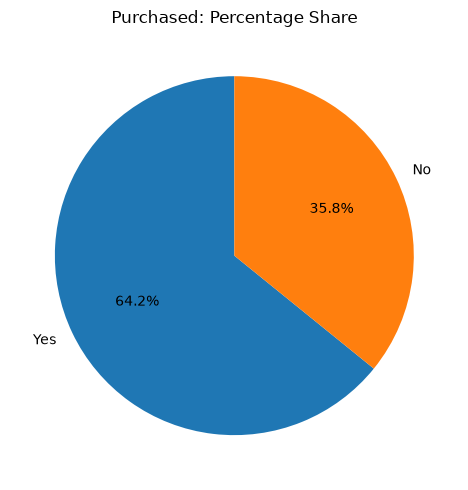

In [23]:
counts = df["Purchased"].value_counts()
plt.figure(figsize=(5,5))
plt.pie(counts.values, labels=counts.index, autopct="%1.1f%%", startangle=90)
plt.title("Purchased: Percentage Share")
plt.tight_layout()
plt.show()

# Explanation
Each slice shows the proportion of customers in a purchase category. Large differences may indicate target imbalance. Avoid using too many slices because similar percentages become hard to compare.